# Lab 4 — Data Analysis and Visualization

Dataset: Sample Superstore (retail transactions — `order_date`, `region`, `category`,
`sub_category`, `discount`, `profit`, `sales`)


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
from scipy import stats

CATEGORY_COLORS = {
    "Furniture": "#2A6F77",       # deep teal
    "Office Supplies": "#D8973C", # amber
    "Technology": "#BF4342",      # brick red
}
ACCENT_HIST   = "#3E7C7C"   # teal-green for histogram bars
ACCENT_KDE    = "#D8973C"   # amber for KDE line
ACCENT_LINE1  = "#8AA29E"   # muted sage (raw monthly line)
ACCENT_LINE2  = "#BF4342"   # brick red (rolling average line)
ACCENT_LOSS   = "#7A2048"   # plum for loss/annotation markers
PROFITABLE_COLORS = {True: "#2A6F77", False: "#BF4342"}

# custom sequential colormap: cream -> deep plum (instead of default 'Blues'/'Greens')
CUSTOM_CMAP = mcolors.LinearSegmentedColormap.from_list(
    "cream_plum", ["#FFF6E9", "#D8973C", "#7A2048"]
)

sns.set_style("whitegrid")
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.edgecolor"] = "#444444"


## Load & Clean the Dataset


In [5]:
df = pd.read_csv("Sample - Superstore.csv", encoding="latin1")

# standardize column names
df.columns = [c.strip().lower().replace(" ", "_").replace("-", "_") for c in df.columns]

# parse dates
df["order_date"] = pd.to_datetime(df["order_date"], format="%m/%d/%Y")
df["ship_date"]  = pd.to_datetime(df["ship_date"], format="%m/%d/%Y")

print("Shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("Null values total:", df.isnull().sum().sum())

df = df.drop_duplicates()
df.to_csv("superstore_cleaned.csv", index=False)
df[["order_date","region","category","sub_category","discount","profit","sales"]].head()


Shape: (9994, 21)
Duplicate rows: 0
Null values total: 0


,order_date,region,category,sub_category,discount,profit,sales
0,2016-11-08,South,Furniture,Bookcases,0.00,41.9136,261.9600
1,2016-11-08,South,Furniture,Chairs,0.00,219.5820,731.9400
2,2016-06-12,West,Office Supplies,Labels,0.00,6.8714,14.6200
3,2015-10-11,South,Furniture,Tables,0.45,-383.0310,957.5775
4,2015-10-11,South,Office Supplies,Storage,0.20,2.5164,22.3680


## 1. Univariate, Properly Read Distribution of sales
Histogram + KDE overlay, skewness, and mean vs. median comparison.

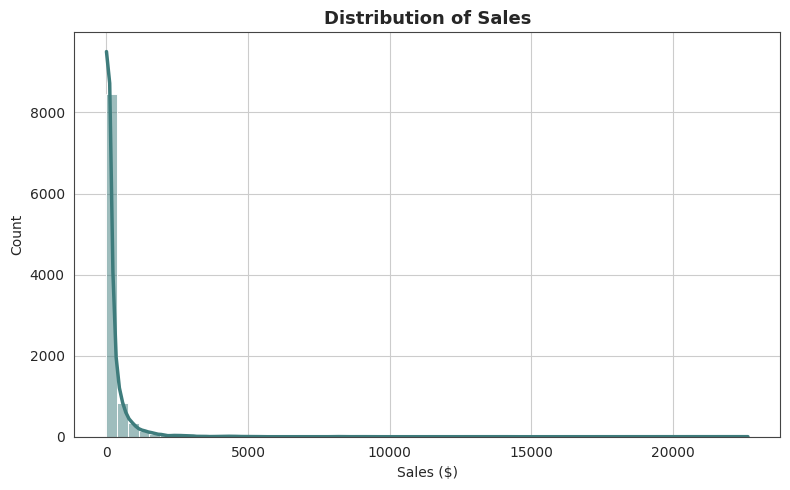

Skewness: 12.97
Mean: 229.86  |  Median: 54.49


In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(df["sales"], bins=60, kde=True, color=ACCENT_HIST,
             line_kws={"color": ACCENT_KDE, "linewidth": 2.5}, ax=ax)
ax.set_title("Distribution of Sales", fontsize=13, weight="bold")
ax.set_xlabel("Sales ($)")
plt.tight_layout()
plt.show()

sales_skew = df["sales"].skew()
sales_mean, sales_median = df["sales"].mean(), df["sales"].median()
print(f"Skewness: {sales_skew:.2f}")
print(f"Mean: {sales_mean:.2f}  |  Median: {sales_median:.2f}")


**Interpretation:** Skewness is **+12.97** (well above the ~0 threshold for symmetry) and the
mean (**$229.86**) is far greater than the median (**$54.49**) — both signal a strongly
**right-skewed** distribution driven by a small number of high-value orders. For this shape, the
mean is a poor summary of a "typical" order since it is pulled upward by the long tail; the
median (or a trimmed mean) better represents typical sales.

## 2. Categorical × Numerical, Beyond the Average — Profit by Category
Violin plot and jittered strip plot of `profit` by `category`, using the same category colors.

/tmp/ipykernel_549/2271630865.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x="category", y="profit", order=order, palette=palette, ax=axes[0])
/tmp/ipykernel_549/2271630865.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(data=df, x="category", y="profit", order=order, palette=palette,


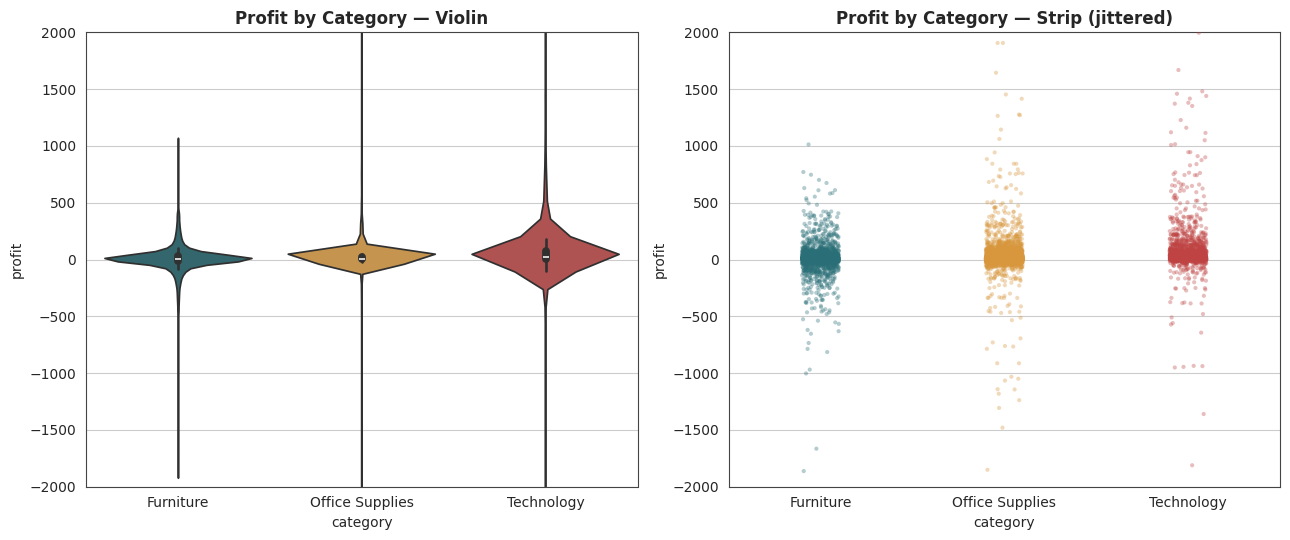

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
order = list(CATEGORY_COLORS.keys())
palette = [CATEGORY_COLORS[c] for c in order]

sns.violinplot(data=df, x="category", y="profit", order=order, palette=palette, ax=axes[0])
axes[0].set_title("Profit by Category — Violin", fontsize=12, weight="bold")
axes[0].set_ylim(-2000, 2000)

sns.stripplot(data=df, x="category", y="profit", order=order, palette=palette,
              jitter=True, alpha=0.35, size=3, ax=axes[1])
axes[1].set_title("Profit by Category — Strip (jittered)", fontsize=12, weight="bold")
axes[1].set_ylim(-2000, 2000)

plt.tight_layout()
plt.show()


**Interpretation:** The **violin plot** better reveals the shape of each group's distribution —
it shows that *Office Supplies* and *Technology* have a narrow, dense body near zero with long
thin tails (heavily skewed, not bimodal), while *Furniture*'s violin is visibly flatter and wider,
indicating a more spread-out, low-margin profit distribution. The strip plot confirms the same
spread but is harder to read for density since thousands of overlapping points blur together even
with jitter and transparency.

## 3. Multivariate Encoding — Discount vs. Profit, colored by Category, sized by Sales

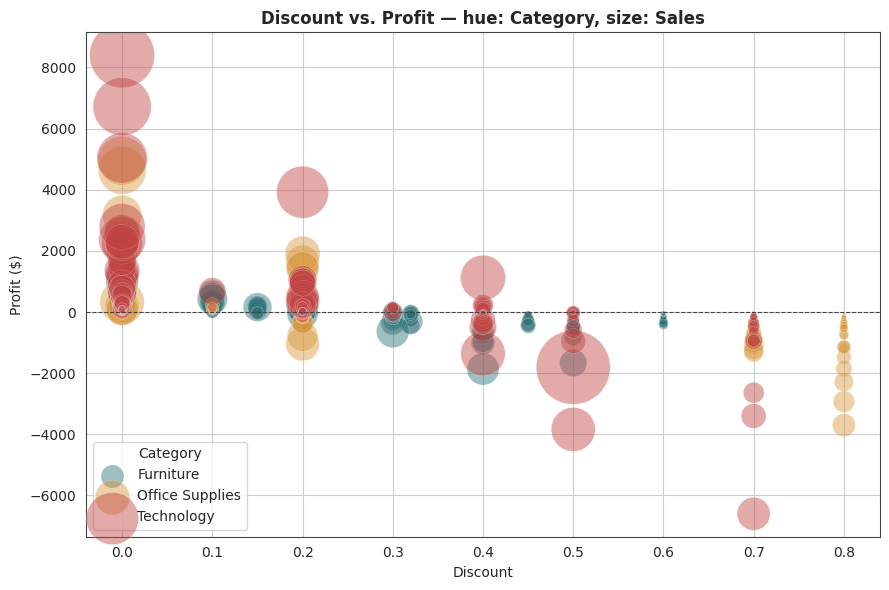

In [5]:
fig, ax = plt.subplots(figsize=(9, 6))
for cat, color in CATEGORY_COLORS.items():
    sub = df[df["category"] == cat]
    ax.scatter(sub["discount"], sub["profit"], s=sub["sales"] / 8,
               color=color, alpha=0.45, label=cat, edgecolor="white", linewidth=0.3)

ax.set_xlabel("Discount")
ax.set_ylabel("Profit ($)")
ax.set_title("Discount vs. Profit — hue: Category, size: Sales", fontsize=12, weight="bold")
ax.axhline(0, color="#444444", linewidth=0.8, linestyle="--")
ax.legend(title="Category", loc="lower left")
plt.tight_layout()
plt.show()


**Interpretation:** The 4-variable encoding shows that the largest-revenue orders (biggest
bubbles) cluster in **Technology**, and it is specifically the large Technology orders at
**high discounts (>0.3)** that fall furthest into negative profit — a pattern invisible in a
plain 2-variable discount-vs-profit scatter, since size (sales) is needed to see that it's the
*big-ticket* Technology deals that turn unprofitable when heavily discounted, not small ones.

## 4. Correlation — Pearson vs. Spearman

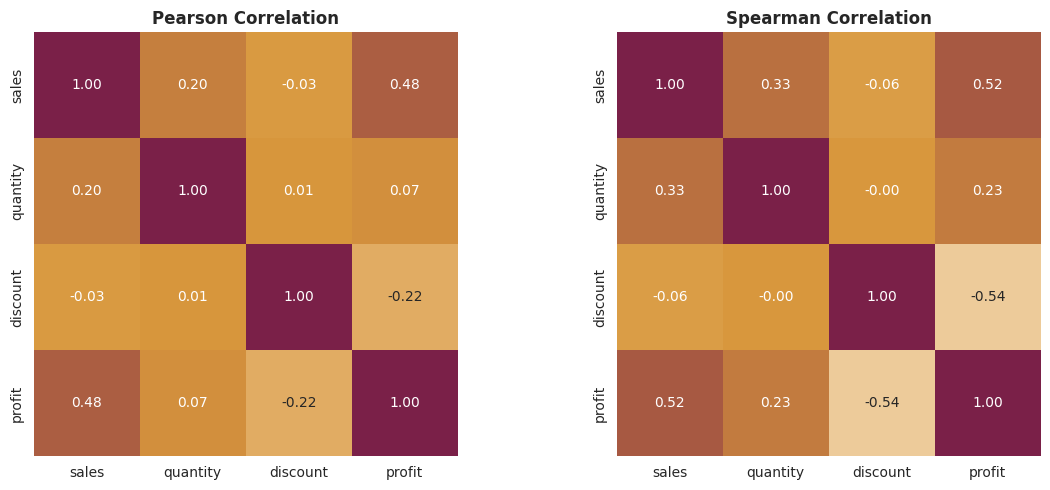

Absolute difference (Pearson vs Spearman):
             sales  quantity  discount    profit
sales     0.000000  0.126631  0.028778  0.039342
quantity  0.126631  0.000000  0.009501  0.168238
discount  0.028778  0.009501  0.000000  0.323863
profit    0.039342  0.168238  0.323863  0.000000


In [6]:
numeric_cols = ["sales", "quantity", "discount", "profit"]
pearson_corr  = df[numeric_cols].corr(method="pearson")
spearman_corr = df[numeric_cols].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(pearson_corr, annot=True, fmt=".2f", cmap=CUSTOM_CMAP, vmin=-1, vmax=1,
            square=True, ax=axes[0], cbar=False)
axes[0].set_title("Pearson Correlation", fontsize=12, weight="bold")
sns.heatmap(spearman_corr, annot=True, fmt=".2f", cmap=CUSTOM_CMAP, vmin=-1, vmax=1,
            square=True, ax=axes[1], cbar=False)
axes[1].set_title("Spearman Correlation", fontsize=12, weight="bold")
plt.tight_layout()
plt.show()

diff = (pearson_corr - spearman_corr).abs()
print("Absolute difference (Pearson vs Spearman):")
print(diff)


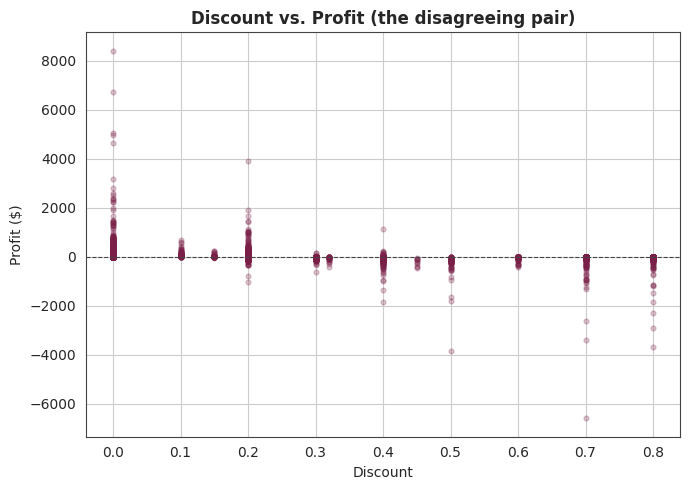

In [7]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df["discount"], df["profit"], alpha=0.25, color=ACCENT_LOSS, s=12)
ax.set_xlabel("Discount")
ax.set_ylabel("Profit ($)")
ax.set_title("Discount vs. Profit (the disagreeing pair)", fontsize=12, weight="bold")
ax.axhline(0, color="#444444", linewidth=0.8, linestyle="--")
plt.tight_layout()
plt.show()


**Interpretation:** `discount` vs. `profit` is the pair where the two methods disagree most:
Pearson = **-0.22** vs. Spearman = **-0.54**. The scatter plot shows why — the relationship is
**non-linear and outlier-heavy**: profit stays roughly flat at low discounts, then drops sharply
once discount exceeds ~0.3–0.4, and a handful of extreme-loss outliers at high discount pull the
linear (Pearson) estimate toward zero. Spearman, which only uses ranks, is not distorted by these
few extreme points and instead captures the strong *monotonic* (discount ↑ → profit ↓) trend more
faithfully. **Caveat:** neither correlation implies causation — the negative relationship could
partly reflect that low-margin products are also the ones marked down most, not solely that
discounting *causes* the loss.

## 5. Layered Aggregation — Region × Category Pivot Table

category,Furniture,Office Supplies,Technology,All
region,,,,
Central,163797.0,167026.0,170416.0,501240.0
East,208291.0,205516.0,264974.0,678781.0
South,117299.0,125651.0,148772.0,391722.0
West,252613.0,220853.0,251992.0,725458.0
All,742000.0,719047.0,836154.0,2297201.0


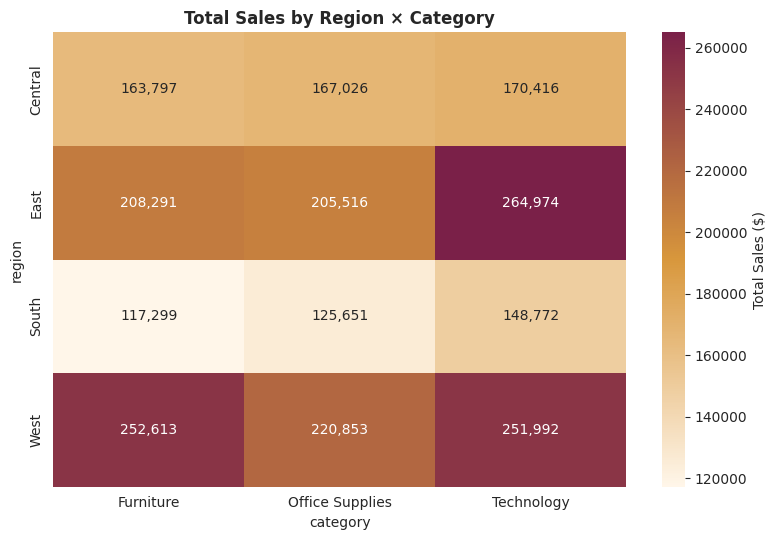

In [8]:
pivot = pd.pivot_table(df, index="region", columns="category", values="sales",
                        aggfunc="sum", margins=True)
display(pivot.round(0))

fig, ax = plt.subplots(figsize=(8, 5.5))
sns.heatmap(pivot.drop(index="All", columns="All"), annot=True, fmt=",.0f",
            cmap=CUSTOM_CMAP, ax=ax, cbar_kws={"label": "Total Sales ($)"})
ax.set_title("Total Sales by Region × Category", fontsize=12, weight="bold")
plt.tight_layout()
plt.show()


**Interpretation:** The **East–Technology** cell contributes the most to overall revenue
(≈ **$264,974**), narrowly ahead of West–Furniture (≈$252,613) and West–Technology
(≈$251,992) — the East and West regions together dominate total sales across all three
categories, while South consistently contributes the least in every category.

## 6. Time-Series — Trend vs. Noise

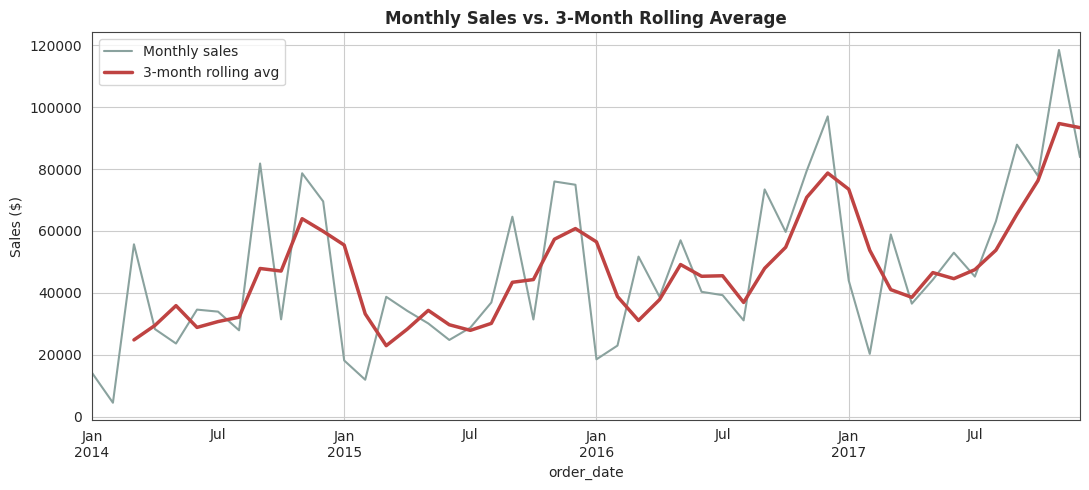

In [9]:
ts = df.set_index("order_date").sort_index()
monthly = ts["sales"].resample("ME").sum()
rolling = monthly.rolling(window=3).mean()

fig, ax = plt.subplots(figsize=(11, 5))
monthly.plot(ax=ax, color=ACCENT_LINE1, linewidth=1.5, label="Monthly sales")
rolling.plot(ax=ax, color=ACCENT_LINE2, linewidth=2.5, label="3-month rolling avg")
ax.set_ylabel("Sales ($)")
ax.set_title("Monthly Sales vs. 3-Month Rolling Average", fontsize=12, weight="bold")
ax.legend()
plt.tight_layout()
plt.show()


**Interpretation:** The raw monthly line jumps sharply month to month (e.g. sharp November/
December spikes each year), making it hard to tell a real trend from short-term noise. The
3-month rolling average smooths those spikes out and makes clear that there is a genuine
**upward year-over-year trend** in sales underneath the recurring seasonal spikes, not just
random volatility.

## 7. Faceting — Discount vs. Profit by Region and Profitability

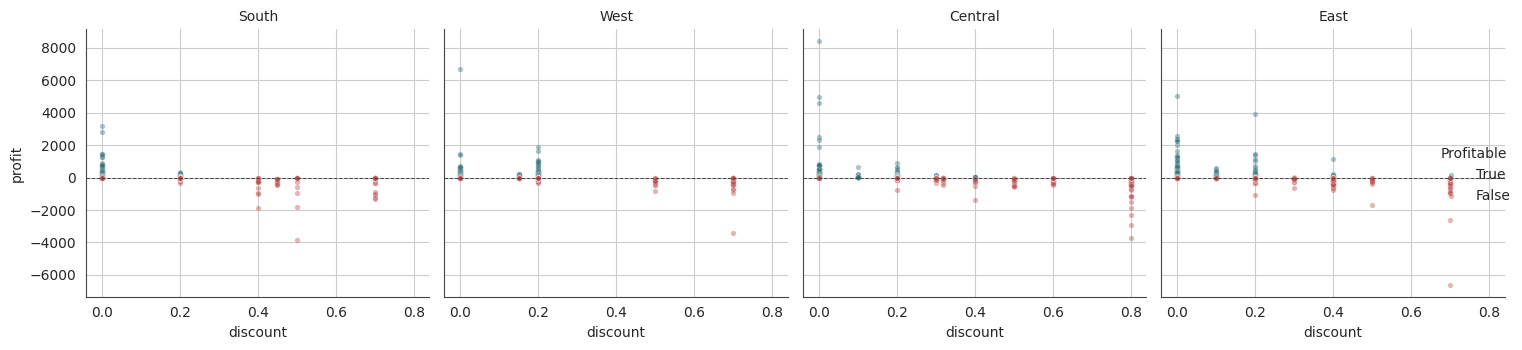

In [10]:
df["profitable"] = df["profit"] > 0

g = sns.FacetGrid(df, col="region", hue="profitable", palette=PROFITABLE_COLORS,
                   col_wrap=4, height=3.6, hue_order=[True, False])
g.map(sns.scatterplot, "discount", "profit", alpha=0.4, s=15)
g.add_legend(title="Profitable")
g.set_titles("{col_name}")
for ax in g.axes.flat:
    ax.axhline(0, color="#444444", linewidth=0.7, linestyle="--")
plt.tight_layout()
plt.show()


**Interpretation:** The **Central** region visibly differs from the others: its points span
much higher discount values (mean discount ≈ **0.24** vs. ≈0.10–0.15 elsewhere) and it has the
highest share of unprofitable orders (≈ **32%** vs. ≈10–19% in West/South/East) — discounting is
both deeper and more strongly associated with losses in Central than in any other region.

## 8. Overplotting + Annotation — Order-Level Discount vs. Profit

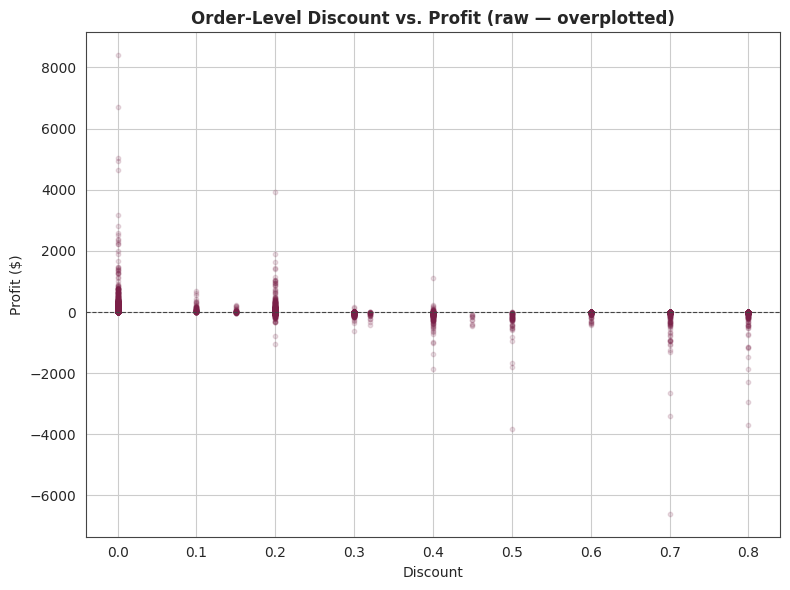

n = 9,994 points -> alpha blending is enough to reveal density; hexbin is reserved for 50k+ points, well beyond this dataset's size.


In [11]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(df["discount"], df["profit"], alpha=0.15, s=10, color=ACCENT_LOSS)
ax.set_xlabel("Discount")
ax.set_ylabel("Profit ($)")
ax.set_title("Order-Level Discount vs. Profit (raw — overplotted)", fontsize=12, weight="bold")
ax.axhline(0, color="#444444", linewidth=0.8, linestyle="--")
plt.tight_layout()
plt.show()
print(f"n = {len(df):,} points -> alpha blending is enough to reveal density; "
      f"hexbin is reserved for 50k+ points, well beyond this dataset's size.")


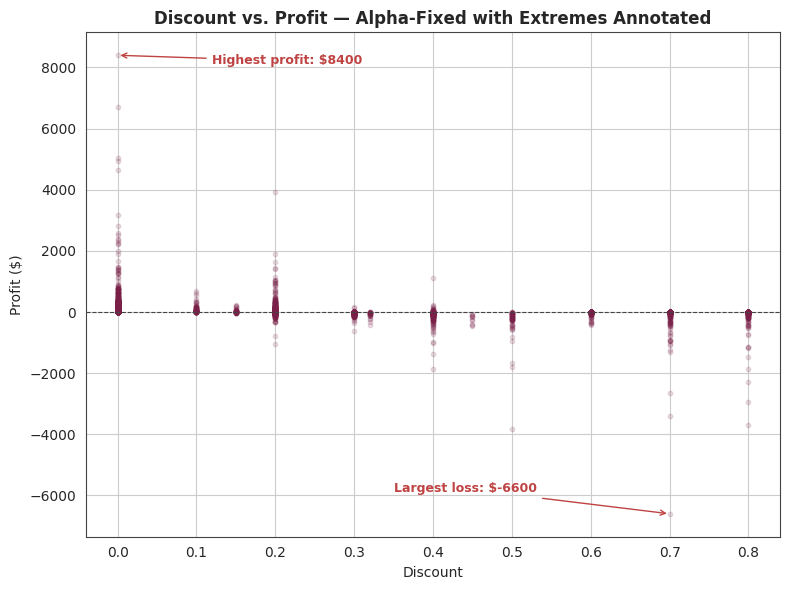

In [12]:
best = df.loc[df["profit"].idxmax()]
worst = df.loc[df["profit"].idxmin()]

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(df["discount"], df["profit"], alpha=0.15, s=10, color=ACCENT_LOSS)
ax.axhline(0, color="#444444", linewidth=0.8, linestyle="--")

ax.annotate(f"Highest profit: ${best['profit']:.0f}",
            xy=(best["discount"], best["profit"]),
            xytext=(best["discount"] + 0.12, best["profit"] - 300),
            arrowprops=dict(arrowstyle="->", color=ACCENT_LINE2),
            fontsize=9, color=ACCENT_LINE2, weight="bold")

ax.annotate(f"Largest loss: ${worst['profit']:.0f}",
            xy=(worst["discount"], worst["profit"]),
            xytext=(worst["discount"] - 0.35, worst["profit"] + 700),
            arrowprops=dict(arrowstyle="->", color=CATEGORY_COLORS["Technology"]),
            fontsize=9, color=CATEGORY_COLORS["Technology"], weight="bold")

ax.set_xlabel("Discount")
ax.set_ylabel("Profit ($)")
ax.set_title("Discount vs. Profit — Alpha-Fixed with Extremes Annotated", fontsize=12, weight="bold")
plt.tight_layout()
plt.show()


**Fix justification:** with **9,994** points, alpha transparency is sufficient to reveal
where points are dense versus sparse; hexbinning is reserved for much larger (50k+) datasets
where even transparency can't separate overlapping regions.